# Preprocessing Technique 2: Encoding Categorical Variables
IT25101160 - Rukmalgoda R.D.D
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Categorical encoding** converts non-numeric or arbitrarily-coded labels into a numeric form that machine learning algorithms can process mathematically. Common approaches include **Label Encoding** (mapping categories to integers, suited to ordinal or binary categories) and **One-Hot Encoding** (creating a separate binary column per category, suited to nominal categories with no inherent order).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [3]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


## 2. Identifying the Categorical Variable
All 9 predictive features in this dataset are already numeric (integer scores 1-10). The one column that behaves as a **categorical variable** is the target itself - **Class** - which uses arbitrary integer codes **2 (benign)** and **4 (malignant)** rather than a clean binary 0/1 label.

In [5]:
print(df['Class'].value_counts())
print("\nUnique values in Class:", sorted(df['Class'].unique()))
print("\nData type:", df['Class'].dtype)

Class
2    458
4    241
Name: count, dtype: int64

Unique values in Class: [np.int64(2), np.int64(4)]

Data type: int64


## 3. Why This Technique Was Needed
- The codes **2** and **4** are **arbitrary identifiers**, not meaningful quantities - a model must not interpret **4** as "twice as much" as **2**. Left as-is, this risks confusing algorithms that assume ordinal/continuous meaning in their inputs (e.g. some distance-based or regression-adjacent methods).
- Scikit-learn classifiers, evaluation functions (**f1_score**, **roc_auc_score**, etc.), and libraries like PyTorch/TensorFlow **expect binary classification labels in {0, 1}** by convention. Re-encoding avoids subtle bugs (e.g. **pos_label** mismatches) later in Step 3 and Step 4 of the assignment.
- A binary 0/1 label is also more interpretable when reporting results: **0 = Benign, 1 = Malignant** directly matches "probability of malignancy" style outputs (e.g. from **predict_prob**a).

In [6]:
# Label-encode the target: 2 (benign) -> 0, 4 (malignant) -> 1
df_encoded = df.copy()
class_map = {2: 0, 4: 1}
df_encoded['Class'] = df_encoded['Class'].map(class_map)

print("Encoding map used:", class_map)
print("\nBefore encoding:\n", df['Class'].value_counts().rename('count'))
print("\nAfter encoding:\n", df_encoded['Class'].value_counts().rename('count'))
assert df_encoded['Class'].isna().sum() == 0, "Encoding introduced unexpected NaNs"
print("\nNo values lost during encoding - all 699 rows mapped successfully.")

Encoding map used: {2: 0, 4: 1}

Before encoding:
 Class
2    458
4    241
Name: count, dtype: int64

After encoding:
 Class
0    458
1    241
Name: count, dtype: int64

No values lost during encoding - all 699 rows mapped successfully.


## 4. EDA Visualization & Interpretation

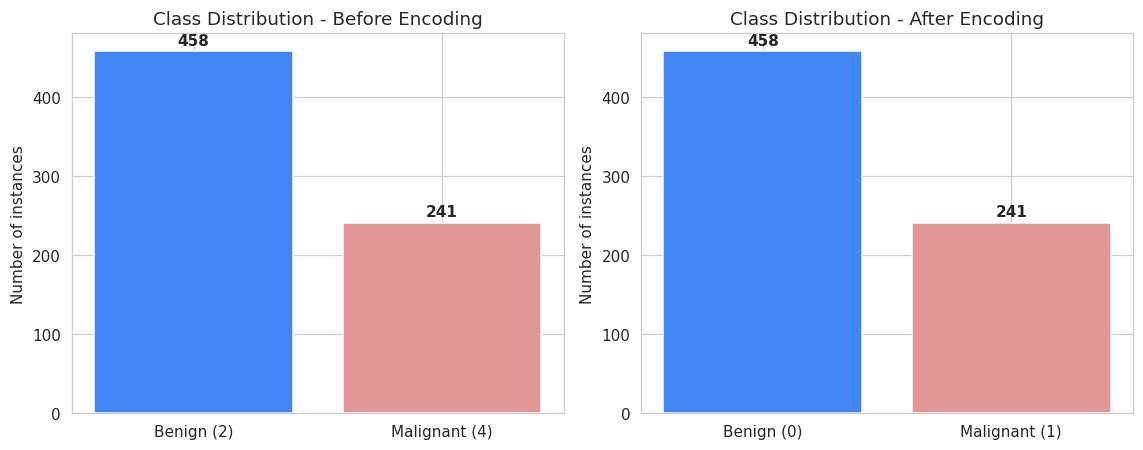

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

labels_before = ['Benign (2)', 'Malignant (4)']
counts_before = df['Class'].value_counts().sort_index().values
axes[0].bar(labels_before, counts_before, color=['#4285F4', '#E39696'])
axes[0].set_title('Class Distribution - Before Encoding')
axes[0].set_ylabel('Number of instances')
for i, v in enumerate(counts_before):
    axes[0].text(i, v + 8, str(v), ha='center', fontweight='bold')

labels_after = ['Benign (0)', 'Malignant (1)']
counts_after = df_encoded['Class'].value_counts().sort_index().values
axes[1].bar(labels_after, counts_after, color=['#4285F4', '#E39696'])
axes[1].set_title('Class Distribution - After Encoding')
axes[1].set_ylabel('Number of instances')
for i, v in enumerate(counts_after):
    axes[1].text(i, v + 8, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/02_class_encoding_distribution.png', bbox_inches='tight')
plt.show()

**Interpretation:** The bar charts confirm the encoding is a **pure relabelling** - counts are identical before and after (458 benign, 241 malignant), only the numeric codes changed. The chart also highlights the **moderate class imbalance** (65.5% vs 34.5%) that will need to be accounted for during model evaluation (e.g. via F1-score and stratified sampling), which is documented further in the "Limitations" analysis of our proposal.

## 5. Summary
| Item | Result |
|---|---|
| Technique | Categorical (label) encoding |
| Column affected | **Class** (target variable) |
| Original codes | 2 = Benign, 4 = Malignant |
| New codes | 0 = Benign, 1 = Malignant |
| Method | Manual label mapping (**dict.map**) - appropriate since there are only 2 unbounded categories with no ordinal relationship |
| Rows affected | All 699 (relabelled, none dropped) |
| Why not One-Hot? | Binary target only needs a single 0/1 column; one-hot would add redundant columns for a 2-class case |